# 02. Dose represented in training

A dose would count as unfamiliar if that concentration had been absent from training. The audit checked the training split for each of the three tested concentrations before treating dose as a measure of novelty.

**Original agent determination:** The agent plotted dose as an exploratory protocol diagnostic and rejected it as a decreasing training-similarity axis because every dose level was represented in training. This entry retains that original curve and rejection.

This notebook reconstructs the June primary run from its original downloads, split files, processing code and saved agent decisions. STATE was evaluated through the official scored-output repositories in that run.

**Portable input setup.** Install `../requirements.txt` in a Python3.11 environment. The first code cell restores the exact offline payloads included in this checkout, verifies their hashes, and then runs the original scored-output analysis. No model inference is performed. Historical saved curves remain visible; a clean run rebuilds its own `computed/` tables. See `../README.md`.

In [1]:
from pathlib import Path
import sys, json
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'recovered_pipeline.py').is_file())
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display, Markdown
from state_inputs import ensure_inputs
print(ensure_inputs())
import recovered_pipeline as rp
import notebook_support as ns


{'profile': 'default', 'verified_files': 226, 'assets': [{'asset': 'state-historical-comparison-tables.tar.gz', 'members': 25, 'source': 'verified_existing_inputs'}, {'asset': 'state-official-score-cache.tar.gz', 'members': 193, 'source': 'verified_existing_inputs'}, {'asset': 'state-historical-annotations.tar.gz', 'members': 8, 'source': 'verified_existing_inputs'}], 'new_model_inference': False}


Matplotlib is building the font cache; this may take a moment.


## Original acquisition and inputs

The original downloader and processing scripts are preserved unchanged under `original/`. The replay resolves their downloads to the recovered cache at the recorded repository revisions, so no current dataset replaces the original bytes. Original downloads, processing and plotting are separate visible steps below.

In [2]:
verification=rp.run_stage('initial')
ns.show_acquisition('initial')


,repo,revision
0,arcinstitute/ST-HVG-Tahoe,ca6b751972493f8448e3256d1340ae70ad43e1e7
1,arcinstitute/ST-SE-Tahoe,03b1971d7cc93a7535fd2e957c6948dba267378b
2,arcinstitute/ST-HVG-Replogle,bb6a9562cbbf1fd152df14cc53b4cc7517c77175
3,arcinstitute/ST-SE-Replogle,e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c
4,arcinstitute/ST-HVG-Parse,827df657cd87063026d2abefd73e99036755ac1b
5,arcinstitute/ST-SE-Parse,fa458ffda8690c5c5bdff080dfdc46b46713043b
6,tahoebio/Tahoe-100M,2dc57900b7981cfcf5e211527169a0b006546a95


Original evaluation used official scored CSVs. The replay loads the original cached bytes at these revisions.
All 55 score filenames and the three metadata downloads are in computed/initial/artifacts/download_revisions.json.
Initial acquisition implementation: original/state_generalizability_20260602_single_controller/scripts/run_state_spectra_audit.py


## Original processing code

These are the original functions used for this analysis. `recovered_pipeline.py` changes their filesystem destinations and uses the original cached downloads; it writes regenerated products only to `computed/`. Set `force=True` in `run_stage` to recompute this stage after its prerequisites.

In [3]:
ns.show_code('initial',2)

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
def load_target_results(manifest):
    cache_dir = SPECTRA / "loaded_target_results"
    cache_dir.mkdir(parents=True, exist_ok=True)
    frames = []
    download_log = []
    for f in result_file_rows(manifest):
        repo = f["repo_id"]
        path = f["path"]
        local = hf_hub_download(repo_id=repo, filename=path, cache_dir=str(CACHE))
        df = pd.read_csv(local)
        dataset, protocol, context, split_id, rep = parse_result_path(repo, path)
        df.insert(0, "source_repo", repo)
        df.insert(1, "source_path", path)
        df.insert(2, "dataset_family", dataset)
        df.insert(3, "protocol", protocol)
        df.insert(4, "context", context)
        df.insert(5, "split_id", split_id)
        df.insert(6, "representation", rep)
        names, doses, units = zip(*[parse_perturbation(x) for x in df["perturbation"].tolist()])
        df["perturbation_name"] = names
        df["dose"] = doses
        df["dose_unit"] = units
        df["perturbation_norm"] = [norm_name(x) for x in names]
        df["perturbation_loose"] = [loose_name(x) for x in names]
        frames.append(df)
        download_log.append({"repo": repo, "path": path, "rows": int(len(df)), "bytes": f.get("size", 0), "local": local})
    all_df = pd.concat(frames, ignore_index=True)
    all_df.to_csv(ROOT / "target_model_results.csv", index=False)
    (ART / "loaded_target_results_manifest.json").write_text(json.dumps(download_log, indent=2))
    return all_df, download_log

```

```python
def load_tahoe_metadata():
    drug_path = hf_hub_download(
        repo_id="tahoebio/Tahoe-100M",
        repo_type="dataset",
        filename="metadata/drug_metadata.parquet",
        cache_dir=str(CACHE),
    )
    gene_path = hf_hub_download(
        repo_id="tahoebio/Tahoe-100M",
        repo_type="dataset",
        filename="metadata/gene_metadata.parquet",
        cache_dir=str(CACHE),
    )
    cell_path = hf_hub_download(
        repo_id="tahoebio/Tahoe-100M",
        repo_type="dataset",
        filename="metadata/cell_line_metadata.parquet",
        cache_dir=str(CACHE),
    )
    return pd.read_parquet(drug_path), pd.read_parquet(gene_path), pd.read_parquet(cell_path)

```

```python
def dose_axis(df: pd.DataFrame):
    sub = df[(df["dataset_family"] == "Tahoe-100M") & (df["protocol"] == "fewshot")].copy()
    sub["dose_level"] = sub["dose"].map({0.05: "D1_low_0.05", 0.5: "D2_mid_0.5", 5.0: "D3_high_5.0", 0.0: "D0_control"})
    return sub

```

## Recomputed sample membership, values and result

In [4]:
display(verification)

{'score_files': 55,
 'score_rows': 39808,
 'chemical_rows': 7288,
 'drug_metadata_rows': 379,
 'comparison': {'rows': 39808,
  'differences': {'source_repo': 0,
   'source_path': 0,
   'perturbation': 0,
   'overlap_at_N': 0,
   'de_sig_genes_recall': 0,
   'pearson_delta': 0,
   'max_tanimoto_to_target_context_train_drug': 0,
   'chem_support_level': 0,
   'target_context_train_drug_count': 0},
  'all_match': True},
 'tie_note': {'nearest_reference_label_differences': 50,
  'all_are_equal_similarity_ties': True,
  'explanation': 'Original code iterates a Python set and chooses the first maximum. Tied nearest-drug labels can differ with hash order; all similarities, level assignments and evaluated outcomes match.'}}

{'rows': 6,
 'differences': {'n_rows': 0,
  'similarity_mean': 0,
  'overlap_at_N_mean': 0,
  'de_sig_genes_recall_mean': 0,
  'pearson_delta_mean': 0},
 'all_match': True}

,subset,axis_col,level,n_rows,n_unique_contexts,n_unique_perturbations,n_unique_drug_context_dose,similarity_mean,similarity_min,similarity_max,...,de_spearman_lfc_sig_median,de_spearman_lfc_sig_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std,mse_delta_mean,mse_delta_median,mse_delta_std,state_de_count_mae,representation
0,Tahoe fewshot dose protocol HVG,dose_level,D1_low_0.05,1340,5,268,1340,0.05,0.05,0.05,...,0.612476,0.163570,0.922906,0.933873,0.064607,0.000244,0.000133,0.000730,126.723881,HVG
1,Tahoe fewshot dose protocol HVG,dose_level,D2_mid_0.5,1339,5,268,1339,0.50,0.50,0.50,...,0.637352,0.163553,0.929640,0.943099,0.080463,0.000595,0.000141,0.005728,144.444361,HVG
2,Tahoe fewshot dose protocol HVG,dose_level,D3_high_5.0,995,5,199,995,5.00,5.00,5.00,...,0.619157,0.139911,0.918031,0.931051,0.062598,0.000568,0.000201,0.001214,140.363819,HVG
3,Tahoe fewshot dose protocol SE,dose_level,D1_low_0.05,1340,5,268,1340,0.05,0.05,0.05,...,0.598463,0.158633,0.912538,0.926540,0.070740,0.000270,0.000161,0.000811,128.728358,SE
4,Tahoe fewshot dose protocol SE,dose_level,D2_mid_0.5,1339,5,268,1339,0.50,0.50,0.50,...,0.616269,0.169250,0.921207,0.934499,0.081838,0.000618,0.000168,0.005865,147.008962,SE
5,Tahoe fewshot dose protocol SE,dose_level,D3_high_5.0,995,5,199,995,5.00,5.00,5.00,...,0.599777,0.148656,0.908694,0.922441,0.061695,0.000607,0.000235,0.001227,140.565829,SE


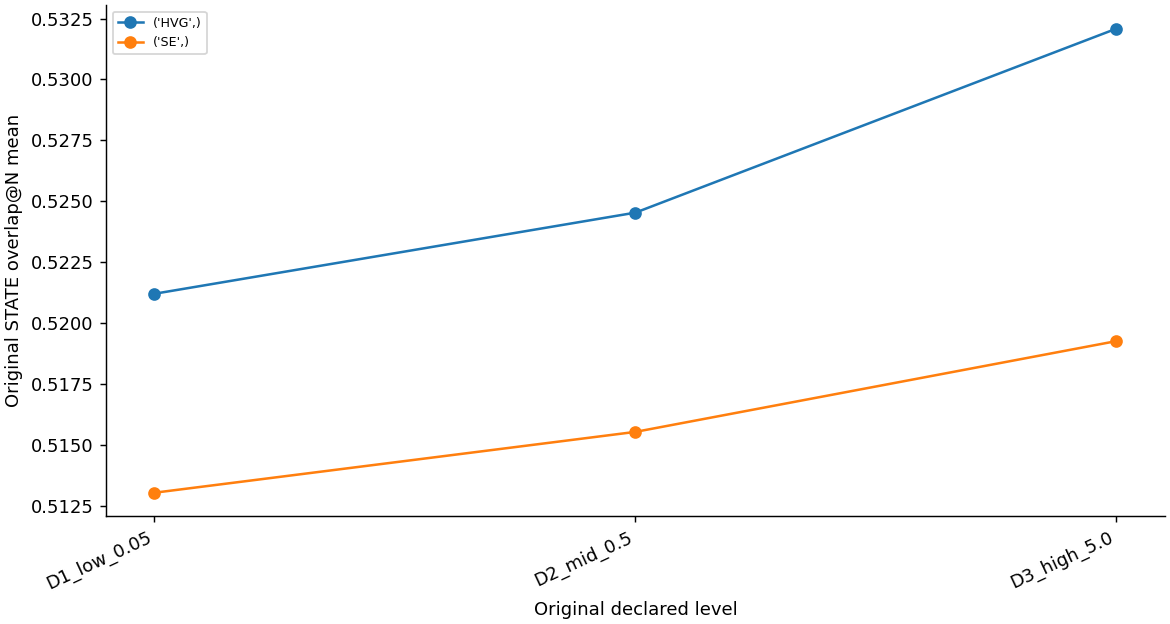

Curves are recalculated means under the original grouping rule. No new confidence bands have been added.


In [5]:
curve=ns.compare_curve('exploratory_tahoe_dose_protocol_curve.csv', initial=True)
ns.show_curve(curve)

## Original agent decision and supporting diagnostics

The following records preserve the agent’s actual determination, including rejected candidates and controls. Their historical status labels are shown as recorded.

In [6]:
ledger=json.loads((rp.INITIAL/'axis_ledger.json').read_text())
display(ledger[1])


{'axis_id': 'A2_tahoe_dose_protocol',
 'status': 'exploratory_invalid_as_spc_similarity',
 'axis_definition': 'Dose level of held-out Tahoe perturbation (0.05, 0.5, 5.0 uM).',
 'reason': 'Dose is prospective, but it is not a decreasing train-test similarity axis in the official splits because all dose levels are represented in training through other perturbations.',
 'primary_artifacts': ['artifacts/exploratory_tahoe_dose_protocol_curve.csv']}

All source files, downloaded inputs and historical outputs are checksummed in `original_manifest.json`. The full preliminary candidate screening and download inventory are retained in notebook `00-original-downloads-and-axis-history.ipynb`.